In [40]:
import pandas as pd

In [41]:
data={
    'area':[500,700,800,1000,1200,1400,1600,1800,2000,2200],
    'price':[15,21,24,30,36,42,48,54,60,66]
}
data

{'area': [500, 700, 800, 1000, 1200, 1400, 1600, 1800, 2000, 2200],
 'price': [15, 21, 24, 30, 36, 42, 48, 54, 60, 66]}

In [42]:
df=pd.DataFrame(data)
df

,area,price
0,500,15
1,700,21
2,800,24
3,1000,30
4,1200,36
5,1400,42
6,1600,48
7,1800,54
8,2000,60
9,2200,66


In [43]:
df.head()

,area,price
0,500,15
1,700,21
2,800,24
3,1000,30
4,1200,36


In [44]:
df.shape

(10, 2)

In [45]:
df.describe()

,area,price
count,10.000000,10.000000
mean,1320.000000,39.600000
std,576.965241,17.308957
min,500.000000,15.000000
25%,850.000000,25.500000
50%,1300.000000,39.000000
75%,1750.000000,52.500000
max,2200.000000,66.000000


In [46]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   area    10 non-null     int64
 1   price   10 non-null     int64
dtypes: int64(2)
memory usage: 292.0 bytes


In [47]:
df.isnull().sum()

,0
area,0
price,0


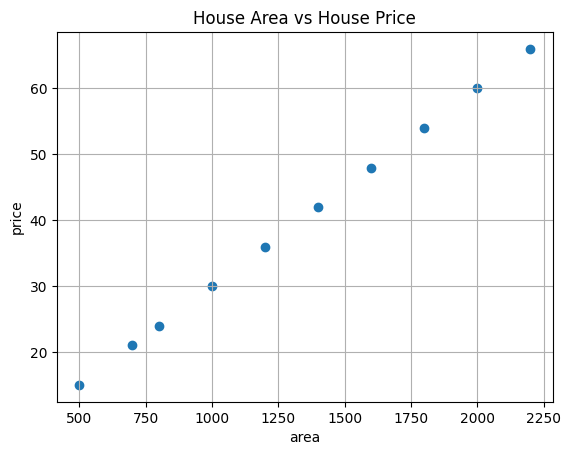

In [48]:
import matplotlib.pyplot as plt
plt.scatter(df['area'],df['price'])
plt.xlabel('area')
plt.ylabel('price')
plt.title("House Area vs House Price")
plt.grid()
plt.show()

In [49]:
x=df[['area']]
y=df['price']

In [50]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [51]:
x_train

,area
5,1400
0,500
7,1800
2,800
9,2200
4,1200
3,1000
6,1600


In [52]:
x_test

,area
8,2000
1,700


In [53]:
from sklearn.linear_model import LinearRegression
model=LinearRegression()
model.fit(x_train,y_train)

LinearRegression()

In [54]:
y_pred=model.predict(x_test)
y_pred

array([60., 21.])

In [55]:
result=pd.DataFrame({
    "area":x_test['area'].values,
    "Actual price":y_test.values,
    "Predicted price":y_pred,
})
result

,area,Actual price,Predicted price
0,2000,60,60.0
1,700,21,21.0


In [56]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np

print("MAE:", mean_absolute_error(y_test, y_pred))
print("MSE:", mean_squared_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R2 Score:", r2_score(y_test, y_pred))

MAE: 1.7763568394002505e-15
MSE: 6.310887241768095e-30
RMSE: 2.5121479338940403e-15
R2 Score: 1.0


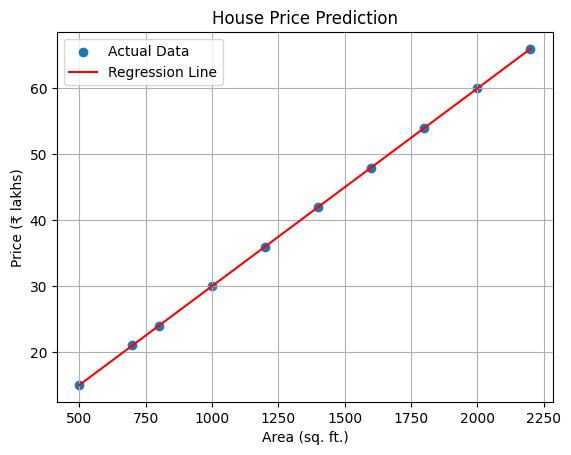

In [57]:
plt.scatter(df["area"], df["price"], label="Actual Data")

plt.plot(
    df["area"],
    model.predict(df[["area"]]),
    color="red",
    label="Regression Line"
)

plt.xlabel("Area (sq. ft.)")
plt.ylabel("Price (₹ lakhs)")
plt.title("House Price Prediction")
plt.legend()
plt.grid(True)
plt.show()

In [58]:
new_house = pd.DataFrame({
    "area": [1500]
})

predicted_price = model.predict(new_house)

print("Predicted House Price:", predicted_price[0], "lakhs")

Predicted House Price: 45.0 lakhs
